# $$ HeliosTrack – Behavior\ Detection\ with\ CMI\ Data | v1.1$$

#  Setup & Overview

In [ ]:
import os
import random
import tensorflow as tf
from tqdm import tqdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score

def set_seed(seed=42):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

SEED = 42
set_seed(SEED)

In [2]:
# Load the datasets
TRAIN_DF = pd.read_csv("/kaggle/input/cmi-detect-behavior-with-sensor-data/train.csv",index_col=0)
TEST_DF = pd.read_csv("/kaggle/input/cmi-detect-behavior-with-sensor-data/test.csv",index_col=0)
TRAIN_DEM_DF = pd.read_csv("/kaggle/input/cmi-detect-behavior-with-sensor-data/train_demographics.csv")
TEST_DEM_DF = pd.read_csv("/kaggle/input/cmi-detect-behavior-with-sensor-data/test_demographics.csv")

# Load datasets (on Colab)
# import os
# TRAIN_DF = pd.read_csv(os.path.join(cmi_detect_behavior_with_sensor_data_path, 'train.csv'))
# TEST_DF = pd.read_csv(os.path.join(cmi_detect_behavior_with_sensor_data_path, 'test.csv'))
# TRAIN_DEM_DF = pd.read_csv(os.path.join(cmi_detect_behavior_with_sensor_data_path, 'train_demographics.csv'))
# TEST_DEM_DF = pd.read_csv(os.path.join(cmi_detect_behavior_with_sensor_data_path, 'test_demographics.csv'))

## IMU only

In [3]:
# Keep only IMU features (drop thm_ and tof_ features from TRAIN and TEST)
NON_IMU_FEATURES = [col for col in TRAIN_DF.columns if col.startswith('thm_') or col.startswith('tof_')]
TRAIN_DF = TRAIN_DF.drop(NON_IMU_FEATURES, axis=1)
TEST_DF = TEST_DF.drop(NON_IMU_FEATURES, axis=1)

## Data Check

In [4]:
# Print helper function
def print_with_sep(text,sep="=",n=20):
  print("\n")
  print(sep*n)
  print(text)
  print(sep*n)

# Check shapes of all 4 datasets
datasets = {'TRAIN_DF': TRAIN_DF, 'TEST_DF': TEST_DF, 'TRAIN_DEM_DF': TRAIN_DEM_DF, 'TEST_DEM_DF': TEST_DEM_DF}

# Check shapes
print_with_sep("Shapes")
for name, df in datasets.items():
  print(f"{name} shape: {df.shape}")

# Check duplicates
print_with_sep("Duplicates")
for name, df in datasets.items():
  print(f"{name} duplicates: {df.duplicated().sum()}")

# Check nans
print_with_sep("NaNs")
for name, df in datasets.items():
  print(f"{name} NaNs: {df.isnull().sum().sum()}")

# Check col difference
print_with_sep("Columns not in test")
print(set(TRAIN_DF.columns).difference(set(TEST_DF.columns)))



Shapes
TRAIN_DF shape: (574945, 15)
TEST_DF shape: (107, 10)
TRAIN_DEM_DF shape: (81, 8)
TEST_DEM_DF shape: (2, 8)


Duplicates
TRAIN_DF duplicates: 0
TEST_DF duplicates: 0
TRAIN_DEM_DF duplicates: 0
TEST_DEM_DF duplicates: 0


NaNs
TRAIN_DF NaNs: 14768
TEST_DF NaNs: 0
TRAIN_DEM_DF NaNs: 0
TEST_DEM_DF NaNs: 0


Columns not in test
{'orientation', 'gesture', 'behavior', 'phase', 'sequence_type'}


In [5]:
# Check descriptive stats
print_with_sep("Descriptive Statistics")
for name, df in datasets.items():
  print(f"{name} Description:")
  display(df.describe(include='all').T.replace(np.nan,'-').style.background_gradient(cmap='Blues',subset='count'))
  print("\n")



Descriptive Statistics
TRAIN_DF Description:


/tmp/ipykernel_19/1076100023.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(df.describe(include='all').T.replace(np.nan,'-').style.background_gradient(cmap='Blues',subset='count'))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sequence_type,574945.000000,2,Target,344058,-,-,-,-,-,-,-
sequence_id,574945.000000,8151,SEQ_015261,700,-,-,-,-,-,-,-
sequence_counter,574945.000000,-,-,-,43.645234,45.717673,0.000000,17.000000,35.000000,54.000000,699.000000
subject,574945.000000,81,SUBJ_040733,10848,-,-,-,-,-,-,-
orientation,574945.000000,4,Seated Straight,188120,-,-,-,-,-,-,-
behavior,574945.000000,4,Performs gesture,255817,-,-,-,-,-,-,-
phase,574945.000000,2,Transition,319128,-,-,-,-,-,-,-
gesture,574945.000000,18,Text on phone,58462,-,-,-,-,-,-,-
acc_x,574945.000000,-,-,-,1.639980,5.781259,-34.585938,-2.964844,2.972656,6.343750,46.328125
acc_y,574945.000000,-,-,-,1.790704,5.003945,-24.402344,-2.121094,0.695312,6.816406,27.183594




TEST_DF Description:


/tmp/ipykernel_19/1076100023.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(df.describe(include='all').T.replace(np.nan,'-').style.background_gradient(cmap='Blues',subset='count'))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
sequence_id,107.000000,2,SEQ_000001,56,-,-,-,-,-,-,-
sequence_counter,107.000000,-,-,-,26.308411,15.615311,0.000000,13.000000,26.000000,39.500000,55.000000
subject,107.000000,2,SUBJ_055840,56,-,-,-,-,-,-,-
acc_x,107.000000,-,-,-,2.901249,5.703883,-4.523438,-3.929688,6.667969,7.529297,10.160156
acc_y,107.000000,-,-,-,5.978899,3.506251,-5.257812,6.130859,6.906250,8.474609,8.957031
acc_z,107.000000,-,-,-,-0.696116,3.636473,-5.093750,-3.390625,-2.605469,0.916016,11.113281
rot_w,107.000000,-,-,-,0.355116,0.054754,0.150818,0.324280,0.359436,0.378235,0.485718
rot_x,107.000000,-,-,-,-0.104678,0.246390,-0.544495,-0.240631,-0.189758,0.170746,0.199585
rot_y,107.000000,-,-,-,-0.042413,0.681530,-0.703430,-0.637482,-0.589478,0.786469,0.827820
rot_z,107.000000,-,-,-,-0.210948,0.544197,-0.887878,-0.662781,-0.558167,0.457977,0.575623


... (2 outputs left out)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
subject,81.000000,81,SUBJ_064387,1,-,-,-,-,-,-,-
adult_child,81.000000,-,-,-,0.518519,0.502770,0.000000,0.000000,1.000000,1.000000,1.000000
age,81.000000,-,-,-,21.814815,10.289693,10.000000,13.000000,22.000000,27.000000,53.000000
sex,81.000000,-,-,-,0.617284,0.489078,0.000000,0.000000,1.000000,1.000000,1.000000
handedness,81.000000,-,-,-,0.876543,0.331010,0.000000,1.000000,1.000000,1.000000,1.000000
height_cm,81.000000,-,-,-,167.993827,10.605863,135.000000,163.000000,170.000000,174.000000,190.500000
shoulder_to_wrist_cm,81.000000,-,-,-,51.580247,4.888415,41.000000,49.000000,52.000000,55.000000,71.000000
elbow_to_wrist_cm,81.000000,-,-,-,25.469136,3.025254,18.000000,24.000000,25.000000,27.000000,44.000000




TEST_DEM_DF Description:


/tmp/ipykernel_19/1076100023.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  display(df.describe(include='all').T.replace(np.nan,'-').style.background_gradient(cmap='Blues',subset='count'))


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
subject,2.000000,2,SUBJ_016452,1,-,-,-,-,-,-,-
adult_child,2.000000,-,-,-,0.500000,0.707107,0.000000,0.250000,0.500000,0.750000,1.000000
age,2.000000,-,-,-,19.000000,8.485281,13.000000,16.000000,19.000000,22.000000,25.000000
sex,2.000000,-,-,-,0.500000,0.707107,0.000000,0.250000,0.500000,0.750000,1.000000
handedness,2.000000,-,-,-,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
height_cm,2.000000,-,-,-,171.000000,8.485281,165.000000,168.000000,171.000000,174.000000,177.000000
shoulder_to_wrist_cm,2.000000,-,-,-,52.000000,0.000000,52.000000,52.000000,52.000000,52.000000,52.000000
elbow_to_wrist_cm,2.000000,-,-,-,25.000000,2.828427,23.000000,24.000000,25.000000,26.000000,27.000000


# Target Analysis

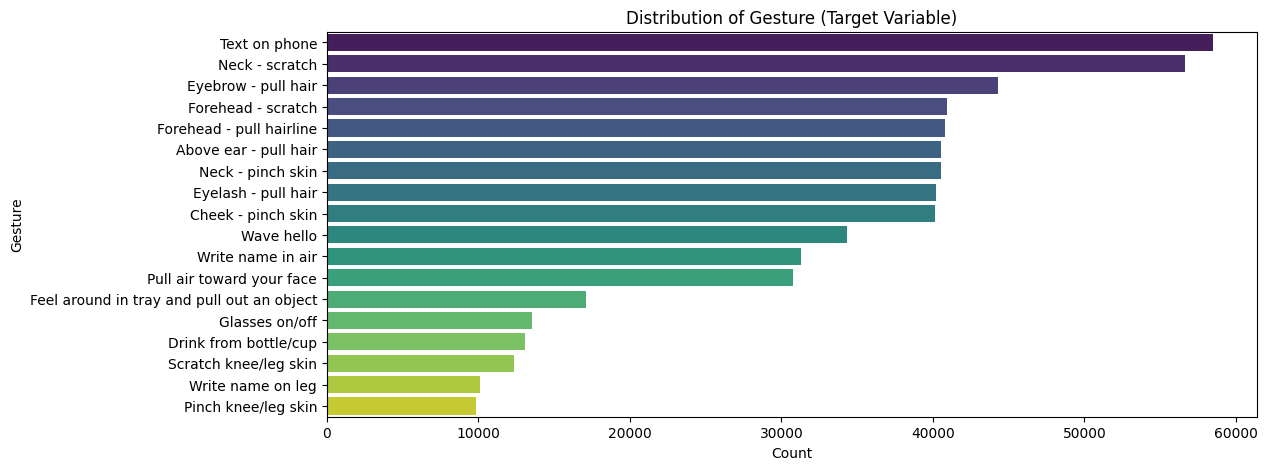

In [6]:
# Identify target
target = 'gesture'

# Distribution of the target variable
plt.figure(figsize=(12, 5))
sns.countplot(data=TRAIN_DF, y=target, order = TRAIN_DF[target].value_counts().index, palette='viridis')
plt.title(f'Distribution of {target.capitalize()} (Target Variable)')
plt.xlabel('Count')
plt.ylabel(f'{target.capitalize()}')
plt.show()

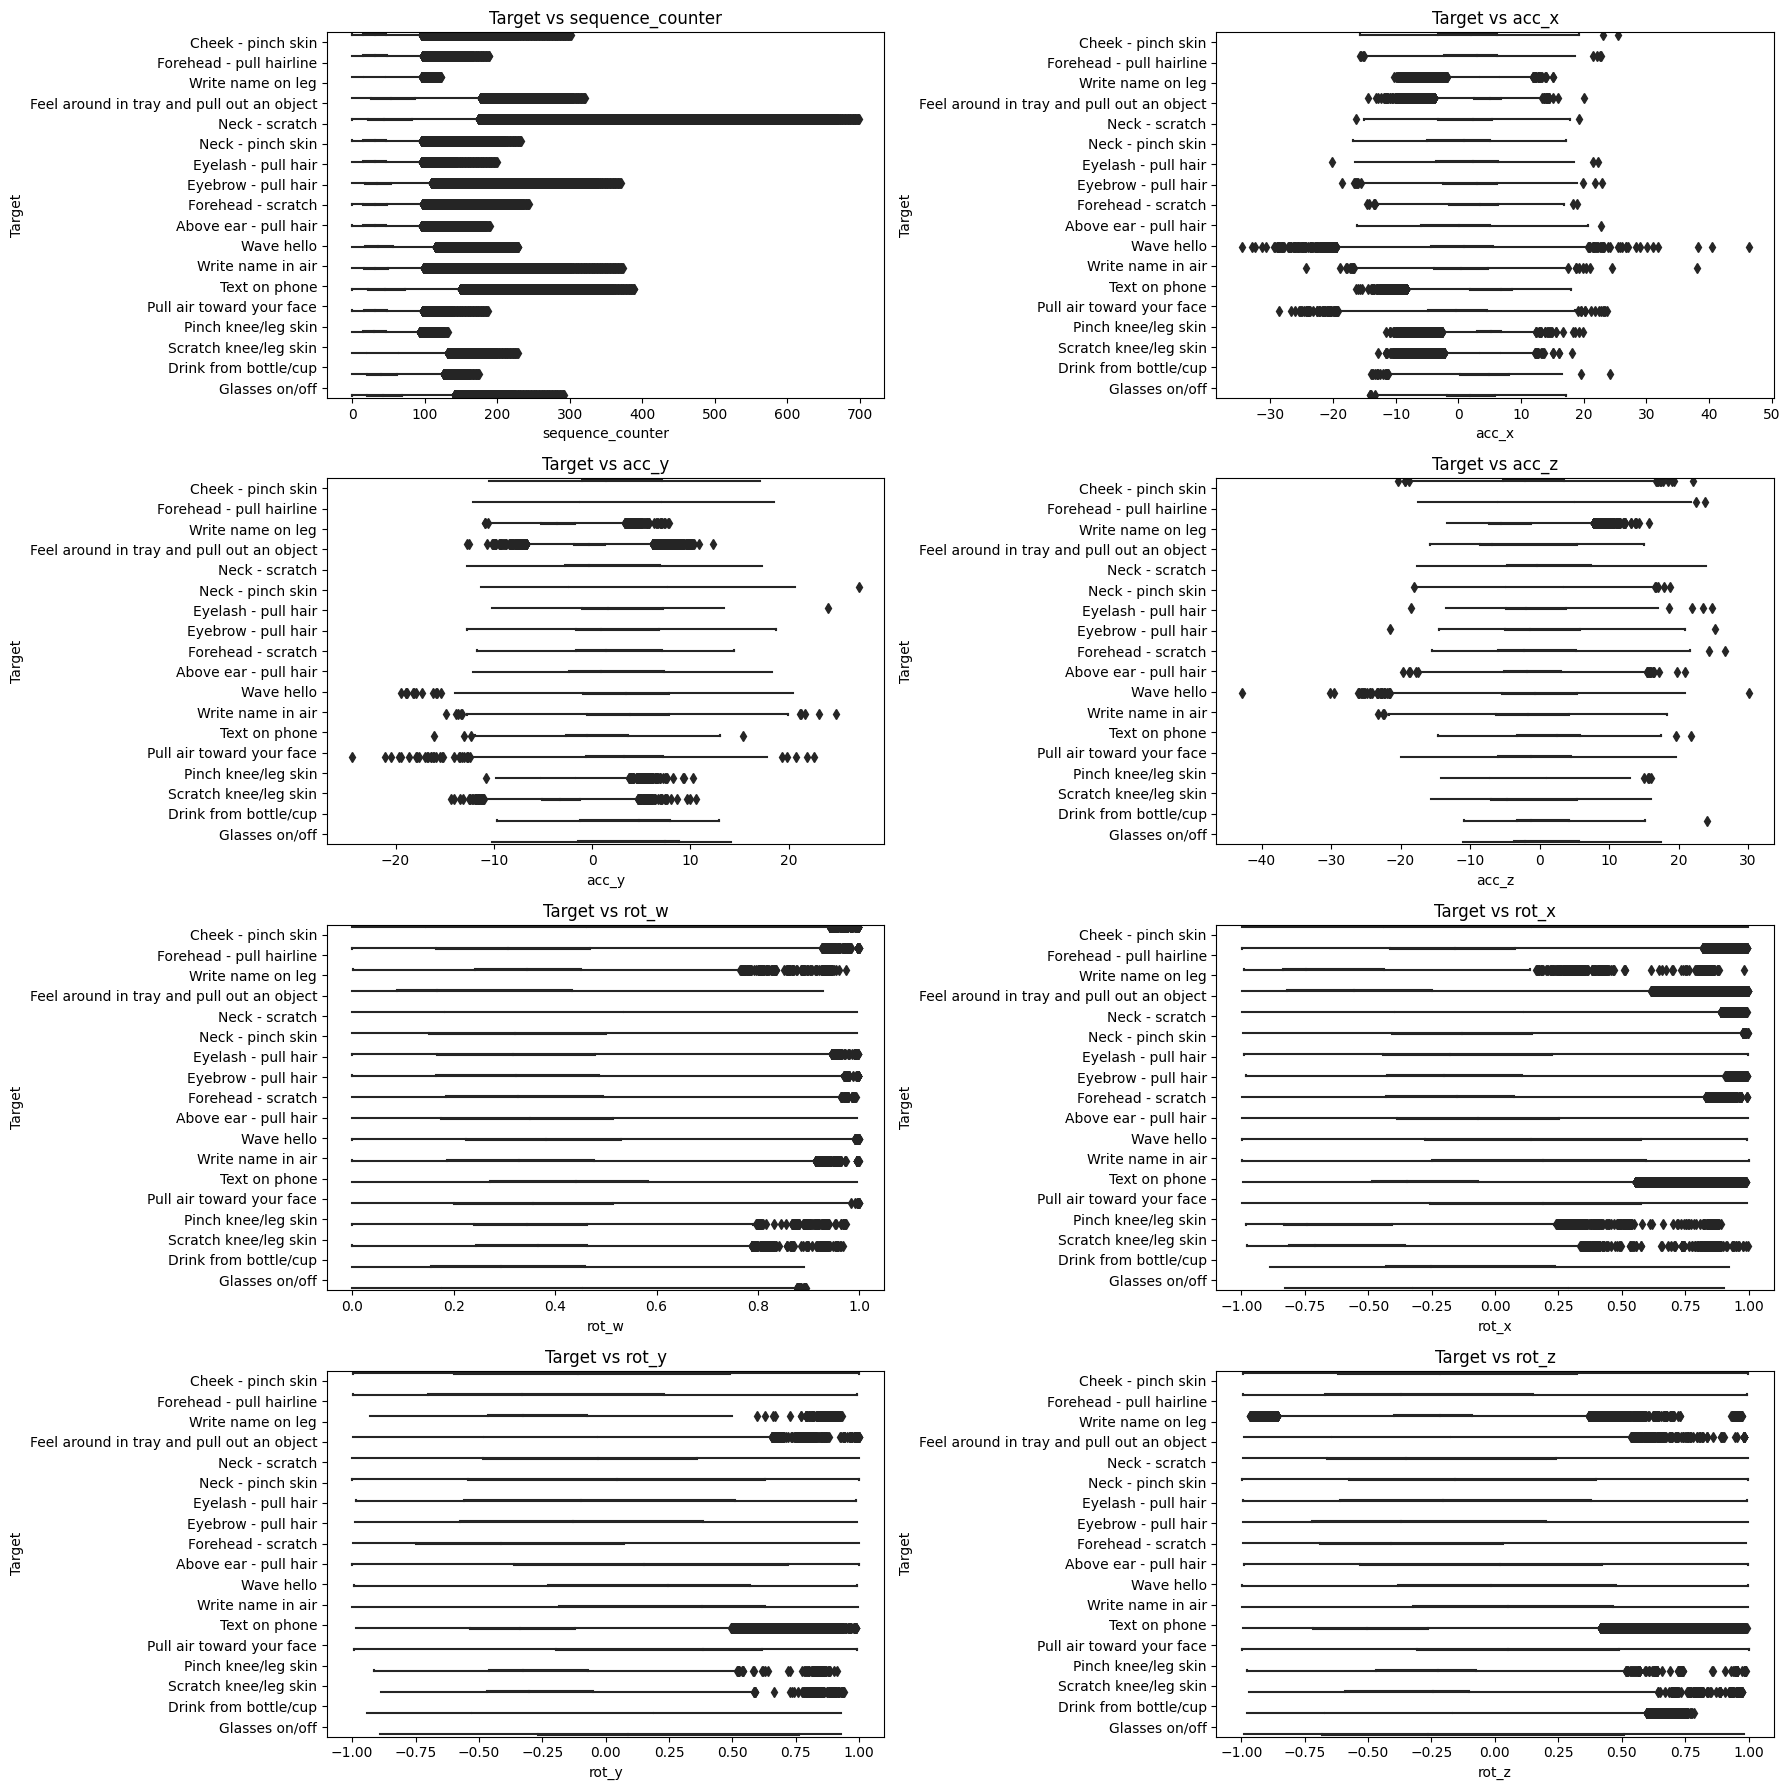

In [7]:
# Relationship between numerical features and the target variable (using boxplots)

# Get the numerical features excluding the target and the index
numerical_features = TRAIN_DF.select_dtypes(include=np.number).columns.tolist()

# Set up the subplot grid
fig, axes = plt.subplots(4, 2, figsize=(18, 3 * 6))
axes = axes.flatten()

# Iterate through the numerical features and create boxplots
for i, feature in enumerate(numerical_features):
    sns.boxplot(y=target, x=feature, data=TRAIN_DF, ax=axes[i], hue = target, palette='viridis')
    axes[i].set_title(f'Target vs {feature}')
    axes[i].set_ylabel('Target')
    axes[i].set_xlabel(feature)
    axes[i].legend_.remove()

plt.tight_layout()
plt.show()

#  Visualize Data Distribution (Univariate Analysis)

[commented out to not exceed 15 mins]

## Numeric Features

In [8]:
# # Perform univariate analysis for each numerical variable
# for variable in TRAIN_DF.select_dtypes(include='number'):
#     # Create subplots
#     fig, axes = plt.subplots(1, 2, figsize=(14, 5))
#     annot_kws = {'xy': (0.70, 0.75), 'xycoords': 'axes fraction', 'fontsize': 10}

#     # Box plot
#     sns.boxplot(data=TRAIN_DF, x=variable, ax=axes[0])
#     axes[0].set_xlabel(variable)
#     axes[0].set_title(f"Box Plot of {variable}")

#     # Histogram
#     sns.histplot(data=TRAIN_DF, x=variable, kde=True, bins=30, ax=axes[1])
#     axes[1].set_xlabel(variable)
#     axes[1].set_ylabel("Frequency")
#     axes[1].set_title(f"Histogram of {variable} [Train]")
#     # axes[1].legend()
#     axes[1].annotate(f"Skewness (TRAIN): {TRAIN_DF[variable].skew():.2f}\nKurtosis (TRAIN): {TRAIN_DF[variable].kurt():.2f}",
#                      xy=annot_kws['xy'], xycoords=annot_kws['xycoords'], fontsize=annot_kws['fontsize'])


#     # Adjust spacing and show
#     plt.tight_layout()
#     plt.show()

## Categorical features

In [9]:
# TRAIN_DF.select_dtypes(exclude='number').columns.difference([target]+['row_id', 'sequence_id'])

In [10]:
# # Define features to investigate
# cat_cols = TRAIN_DF.select_dtypes(exclude='number').columns.difference([target]+['row_id', 'sequence_id','subject'])

# # Visualise categorical variables
# fig, axes = plt.subplots(2,2,figsize=(15, 5))
# ax = axes.flatten()

# for i, col in enumerate(TRAIN_DF[cat_cols]):
#     sns.countplot(data=TRAIN_DF, y=col, order = TRAIN_DF[col].value_counts().index, palette='viridis', ax=ax[i])

# plt.tight_layout()

# 🛠 Feature Engineer

In [11]:
import numpy as np
import pandas as pd
from scipy.spatial.transform import Rotation as R

def compute_angular_features(df, seq_col='sequence_id', sampling_rate=200):
    dt = 1.0 / sampling_rate
    results = []

    for _, group in df.groupby(seq_col):
        quats = group[["rot_x", "rot_y", "rot_z", "rot_w"]].to_numpy()

        omega = np.zeros((len(quats), 3))  # fill with zeros first

        for i in range(len(quats)-1):
            # Start a try loop to avoid invalid (zero norm) quaternions
            try:
                q1 = quats[i]
                q2 = quats[i+1]

                # Convert to Rotation object
                r1 = R.from_quat(q1)
                r2 = R.from_quat(q2)

                # Compute relative rotations (t -> t+1)
                delta = r2 * r1.inv()

                # Convert to rotation vectors
                omega[i+1] = delta.as_rotvec() / dt

            except Exception:
                # if anything goes wrong, keep zeros
                pass

        # angular acceleration = diff of omega
        alpha = np.zeros_like(omega)
        alpha[1:] = np.diff(omega, axis=0) / dt

        # Append
        group = group.copy()
        group[["omega_x", "omega_y", "omega_z"]] = omega
        group[["alpha_x", "alpha_y", "alpha_z"]] = alpha
        results.append(group)
        
    return pd.concat(results, ignore_index=True)


In [12]:
def add_physics_features(
    data,
    seq_col = "sequence_id",
    time_col = "sequence_counter",
    use_bfill = True,
    add_cross_terms = False,
    add_stats_features = False
):

    ε = 1e-8
    df = data.copy()

    # # sort within each sequence to ensure correct differencing
    # df = df.sort_values([seq_col, time_col])

    # Compute angular features
    df = compute_angular_features(df, seq_col=seq_col)

    # numeric columns except the counter
    num_cols = df.select_dtypes(include=np.number).columns.difference([time_col])
    
    # per-sequence imputation: forward-fill, optionally backward-fill (beware of leakage)
    if use_bfill:
        df[num_cols] = df.groupby(seq_col)[num_cols].apply(lambda x:x.ffill().bfill()).reset_index(level=0, drop=True)
        df[num_cols] = df.groupby(seq_col)[num_cols].apply(lambda x:x.fillna(x.min()).fillna(0)).reset_index(level=0, drop=True) # fill remaining nans
    else:
        df[num_cols] = df.groupby(seq_col)[num_cols].apply(lambda x:x.ffill()).reset_index(level=0, drop=True)
        df[num_cols] = df.groupby(seq_col)[num_cols].apply(lambda x:x.fillna(x.min()).fillna(0)).reset_index(level=0, drop=True) # fill remaining nans

    # --- ACCELERATION FEATURES ---
    acc_cols = [c for c in df.columns if c.startswith("acc")]
    for col in acc_cols:
        df[f"diff1_{col}"] = df.groupby(seq_col)[col].diff() # jerk
        
    # --- ROTATION FEATURES ---
    rot_cols = [c for c in df.columns if c.startswith("alpha")]
    for col in rot_cols:
        df[f"diff1_{col}"] = df.groupby(seq_col)[col].diff() # angular jerk 

    # --- ACCELERATION AND ROTATION MAGNITUDES ---
    df["acc_mag"] = np.sqrt(df["acc_x"]**2 + df["acc_y"]**2 + df["acc_z"]**2)
    df["rot_mag"] = np.sqrt(df["alpha_x"]**2 + df["alpha_y"]**2 + df["alpha_z"]**2)
    
    # fill NaNs introduced by diff with 0
    diff_mask = [c for c in df.columns if c.startswith("diff")]
    df[diff_mask] = df[diff_mask].fillna(0.0)

    return df


In [13]:
# Test function on TEST_DF
display(add_physics_features(TEST_DF))

,sequence_id,sequence_counter,subject,acc_x,acc_y,acc_z,rot_w,rot_x,rot_y,rot_z,...,alpha_y,alpha_z,diff1_acc_x,diff1_acc_y,diff1_acc_z,diff1_alpha_x,diff1_alpha_y,diff1_alpha_z,acc_mag,rot_mag
0,SEQ_000001,0,SUBJ_055840,9.039062,5.261719,0.800781,0.367188,-0.397400,-0.629028,-0.558167,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.489594,0.000000
1,SEQ_000001,1,SUBJ_055840,9.421875,3.460938,-1.113281,0.353882,-0.507141,-0.652710,-0.437683,...,7399.187014,-1832.827234,0.382812,-1.800781,-1.914062,-10816.371747,7399.187014,-1832.827234,10.098971,13232.578052
2,SEQ_000001,2,SUBJ_055840,10.160156,2.082031,-3.871094,0.384094,-0.532104,-0.639648,-0.400208,...,-3055.046043,2118.375611,0.738281,-1.378906,-2.757812,20651.754090,-10454.233057,3951.202846,11.070185,10514.540760
3,SEQ_000001,3,SUBJ_055840,9.773438,1.355469,-4.371094,0.387756,-0.531982,-0.634033,-0.405823,...,-4227.141504,-573.626477,-0.386719,-0.726562,-0.500000,-8227.630728,-1172.095462,-2692.002089,10.791841,4558.797856
4,SEQ_000001,4,SUBJ_055840,9.195312,1.011719,-3.222656,0.382751,-0.534180,-0.638367,-0.400818,...,-220.948806,353.819531,-0.578125,-0.343750,1.148438,-2910.212990,4006.192698,927.446009,9.796064,1367.630165
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102,SEQ_000011,46,SUBJ_016452,-4.062500,8.613281,-3.140625,0.362488,0.176758,0.793274,0.456177,...,-85.515336,1643.271524,-0.191406,0.121094,0.304688,311.325883,381.264460,3793.054632,10.027764,1645.932186
103,SEQ_000011,47,SUBJ_016452,-4.140625,8.535156,-3.410156,0.340637,0.166565,0.799927,0.465088,...,1303.139333,1122.093843,-0.078125,-0.078125,-0.269531,430.505259,1388.654669,-521.177681,10.080815,1782.329113
104,SEQ_000011,48,SUBJ_016452,-4.214844,8.414062,-3.371094,0.341675,0.169312,0.799316,0.464417,...,-1053.643623,-2037.792909,-0.074219,-0.121094,0.039062,-763.834952,-2356.782956,-3159.886752,9.996281,2313.012448
105,SEQ_000011,49,SUBJ_016452,-4.406250,8.957031,-3.292969,0.241699,0.135437,0.827820,0.487793,...,5580.520790,7160.864607,-0.191406,0.542969,0.078125,1120.500249,6634.164413,9198.657517,10.511284,9115.974054


In [14]:
TRAIN_DF = add_physics_features(TRAIN_DF)
TEST_DF = add_physics_features(TEST_DF)

#  Keras

## Data preparation for kfold
Prepare the data for StratifiedGroupKFold by creating sequences and identifying the groups and targets.


In [15]:
type_to_num = {
    "Target": 1,
    "Non-Target":0
    }

label_to_num = {
    'Drink from bottle/cup': 0,  # < ------- NON-TARGETS START
    'Feel around in tray and pull out an object': 0,
    'Glasses on/off': 0,
    'Pinch knee/leg skin': 0,
    'Pull air toward your face': 0,
    'Scratch knee/leg skin': 0,
    'Text on phone': 0,
    'Wave hello': 0,
    'Write name in air': 0,
    'Write name on leg': 0,  # < ------- NON-TARGETS END
    'Above ear - pull hair': 1,  # < ------- TARGETS START
    'Cheek - pinch skin': 2,
    'Eyebrow - pull hair': 3,
    'Eyelash - pull hair': 4,
    'Forehead - pull hairline': 5,
    'Forehead - scratch': 6,
    'Neck - pinch skin': 7,
    'Neck - scratch': 8,  # < ------- TARGETS END
}

# Map target (label_to_num)
TRAIN_DF['gesture'].map(label_to_num)

0         2
1         2
2         2
3         2
4         2
         ..
574940    0
574941    0
574942    0
574943    0
574944    0
Name: gesture, Length: 574945, dtype: int64

In [16]:
# Define reverse dictionaries
num_to_label = {v: k for k, v in label_to_num.items()}
num_to_type = {v: k for k, v in type_to_num.items()}

# Leave 0 value in num_to_label as a random non-target type (I don't need to trace back to specific non-target gesture. See challenge overview)
# num_to_label[0] = num_to_type[0]
num_to_label

{0: 'Write name on leg',
 1: 'Above ear - pull hair',
 2: 'Cheek - pinch skin',
 3: 'Eyebrow - pull hair',
 4: 'Eyelash - pull hair',
 5: 'Forehead - pull hairline',
 6: 'Forehead - scratch',
 7: 'Neck - pinch skin',
 8: 'Neck - scratch'}

In [17]:
# Encode target with map
TRAIN_DF['gesture'] = TRAIN_DF['gesture'].map(label_to_num)
TRAIN_DF['gesture'].unique()

array([2, 5, 0, 8, 7, 4, 3, 6, 1])

In [18]:
# Segment data by sequence_id (TRAIN_DF)
features = TRAIN_DF.select_dtypes(include=np.number).columns.difference(['sequence_counter','gesture']).tolist()
train_sequences = []
train_groups = []
targets = []

for sequence_id, group_df in TRAIN_DF.groupby('sequence_id'):
    train_sequences.append(group_df[features].values)
    train_groups.append(group_df['subject'].iloc[0])
    targets.append(group_df['gesture'].iloc[0])

len(train_groups)

8151

In [19]:
# Segment data by sequence_id (TEST_DF)
test_sequences = []
test_groups = []

for sequence_id, group_df in TEST_DF.groupby('sequence_id'):
    test_sequences.append(group_df[features].values)
    test_groups.append(group_df['subject'].iloc[0])

len(test_groups)

2

## Determine Sequence Length

In [ ]:
seq_lengths = [s.shape[0] for s in train_sequences]

plt.figure(figsize=(12, 5))
sns.histplot(seq_lengths, bins=100)
plt.title("Sequence Lengths")
plt.show()

In [21]:
# Convert to pandas Series to use quantile
seq_lengths_series = pd.Series(seq_lengths)

# Calculate the 95th percentile and assign it to MAXLEN
MAXLEN = int(seq_lengths_series.quantile(0.95))
print(f"95th percentile of sequence lengths: {MAXLEN}")

95th percentile of sequence lengths: 127


## Pad Sequences

In [22]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# pad_sequences (train)
X_padded = pad_sequences(
    train_sequences,
    maxlen=MAXLEN,
    dtype='float32',
    padding='post',
    truncating='post',
    value=0
)

In [23]:
# pad_sequences (test)
X_test_padded = pad_sequences(
    test_sequences,
    maxlen=MAXLEN,
    dtype='float32',
    padding='post',
    truncating='post',
    value=0
)

## Stratified Group K-Fold

In [24]:
# Initialise sgkf
sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define y
y = np.array(targets)

# Define folds
folds = list(sgkf.split(X_padded, y, train_groups))

## Function to Build Model

In [25]:
def build_model(input_shape, n_classes):
    inputs = keras.Input(shape=input_shape)

    # Mask padded timesteps
    x = layers.Masking(mask_value=0)(inputs)

    # Bidirectional LSTM
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x); x = layers.Dropout(0.1)(x)
    x = layers.Bidirectional(layers.LSTM(128, return_sequences=True))(x); x = layers.Dropout(0.1)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x); x = layers.Dropout(0.1)(x)
    x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x); x = layers.Dropout(0.1)(x)

    # Global pooling → converts (batch, time, features) → (batch, features)
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(64, activation='relu')(x)
    outputs = layers.Dense(n_classes, activation='softmax')(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

## Training Loop (Cross-validation)

In [26]:
histories = []
oof_preds = np.zeros((len(y), len(np.unique(y))))
test_preds = np.zeros((len(X_test_padded), len(np.unique(y))))

from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
import tensorflow.keras.layers as layers

n_classes = len(np.unique(y))

for fold, (train_idx, val_idx) in enumerate(folds):
    print(f"\n=== Fold {fold+1} ===")

    X_train, X_val = X_padded[train_idx], X_padded[val_idx]
    y_train, y_val = y[train_idx], y[val_idx]

    # Fit scaler on train only
    n_features = X_train.shape[2]
    scaler = StandardScaler()

    # Flatten time axis for fitting scaler
    scaler.fit(
        X_train.reshape(-1, n_features)
    )

    # Compute class weights
    weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_train),
        y=y_train
    )
    # Convert class weights to a dictionary
    class_weight_dict = dict(zip(np.unique(y_train), weights))
    print(class_weight_dict)

    # transform and reshape back
    X_train_scaled = scaler.transform(X_train.reshape(-1, n_features)).reshape(X_train.shape)
    X_val_scaled = scaler.transform(X_val.reshape(-1, n_features)).reshape(X_val.shape)
    X_test_scaled = scaler.transform(X_test_padded.reshape(-1, n_features)).reshape(X_test_padded.shape)

    model = build_model(
        input_shape=(MAXLEN, n_features),
        n_classes=n_classes
    )

    callbacks = [
        keras.callbacks.EarlyStopping(
            patience=5,
            restore_best_weights=True
        )
    ]

    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=50,
        batch_size=32,
        callbacks=callbacks,
        class_weight=class_weight_dict,
        verbose=1
    )

    histories.append(history)

    # Predict OOF and test
    oof_preds[val_idx] = model.predict(X_val_scaled, verbose=0)
    test_preds += model.predict(X_test_scaled)


=== Fold 1 ===
{0: 0.29807956104252403, 1: 1.4202614379084968, 2: 1.4230517354289456, 3: 1.4202614379084968, 4: 1.4147135416666667, 5: 1.4147135416666667, 6: 1.4147135416666667, 7: 1.4147135416666667, 8: 1.4147135416666667}


I0000 00:00:1755710194.425871      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1755710194.426506      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/50


I0000 00:00:1755710206.147073      67 cuda_dnn.cc:529] Loaded cuDNN version 90300


204/204 ━━━━━━━━━━━━━━━━━━━━ 22s 51ms/step - accuracy: 0.2808 - loss: 2.0664 - val_accuracy: 0.3205 - val_loss: 1.8773
Epoch 2/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.4239 - loss: 1.8461 - val_accuracy: 0.4185 - val_loss: 1.6268
Epoch 3/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.4819 - loss: 1.7387 - val_accuracy: 0.4259 - val_loss: 1.6557
Epoch 4/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.5125 - loss: 1.6578 - val_accuracy: 0.4626 - val_loss: 1.5090
Epoch 5/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.5274 - loss: 1.6059 - val_accuracy: 0.4547 - val_loss: 1.5337
Epoch 6/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.5526 - loss: 1.5364 - val_accuracy: 0.5178 - val_loss: 1.3779
Epoch 7/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 10s 47ms/step - accuracy: 0.5625 - loss: 1.5043 - val_accuracy: 0.5355 - val_loss: 1.3368
Epoch 8/50
204/204 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.5829 - loss: 1.4339 - val_accuracy: 0.5

In [27]:
# histories[0].model.predict(X_test_scaled[0])
histories[0].model.predict(X_test_scaled).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


array([4, 4])

## Visualize Training Curves

In [ ]:
# Plot accuracy per fold

# subplots
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
axes = ax.flatten()

for i, h in enumerate(histories):
    sns.lineplot(h.history['val_accuracy'], label=f'Fold {i}', ax=axes[0])

plt.title("Validation Accuracy per Fold")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()


# Plot val_loss per fold
for i, h in enumerate(histories):
    sns.lineplot(h.history['val_loss'], label=f'Fold {i}', ax=axes[1])

plt.title("Validation Loss per Fold")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [29]:
from sklearn.metrics import classification_report

y_oof_pred = oof_preds.argmax(axis=1)

# Get the original gesture class names from the label encoder
gesture_classes = num_to_label.values()

print(
    classification_report(y, y_oof_pred, target_names=gesture_classes)
)

                          precision    recall  f1-score   support

       Write name on leg       0.94      0.88      0.91      3038
   Above ear - pull hair       0.43      0.34      0.38       638
      Cheek - pinch skin       0.32      0.30      0.31       637
     Eyebrow - pull hair       0.25      0.24      0.24       638
     Eyelash - pull hair       0.37      0.45      0.41       640
Forehead - pull hairline       0.47      0.50      0.48       640
      Forehead - scratch       0.51      0.61      0.56       640
       Neck - pinch skin       0.33      0.28      0.30       640
          Neck - scratch       0.31      0.38      0.34       640

                accuracy                           0.57      8151
               macro avg       0.43      0.44      0.44      8151
            weighted avg       0.58      0.57      0.57      8151



# ✅ Submission

In [30]:
test_preds = np.zeros((len(X_test_padded), len(np.unique(y))))

for i,h in enumerate(histories):
    partial_predictions = h.model.predict(X_test_padded)
    test_preds += partial_predictions

test_preds.argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


array([0, 0])

In [31]:
import polars as pl

def predict(sequence: pl.DataFrame, demographics: pl.DataFrame) -> str:

    TEST_DF = sequence.to_pandas()
    TEST_DF = add_physics_features(TEST_DF)

    # Segment data by sequence_id (TEST_DF)
    test_sequences = []
    test_groups = []

    for sequence_id, group_df in TEST_DF.groupby('sequence_id'):
        test_sequences.append(group_df[features].values)
        test_groups.append(group_df['subject'].iloc[0])

    # pad_sequences (test)
    X_test_padded = pad_sequences(
        test_sequences,
        maxlen=MAXLEN,
        dtype='float32',
        padding='post',
        truncating='post',
        value=0
    )

    # transform and reshape back
    X_test_scaled = scaler.transform(X_test_padded.reshape(-1, n_features)).reshape(X_test_padded.shape)

    # Initialize test_preds
    test_preds = np.zeros((len(X_test_scaled), len(np.unique(y))))

    # Loop through partial models
    for i,h in enumerate(histories):
        partial_predictions = h.model.predict(X_test_scaled)
        test_preds += partial_predictions
    
        # Predict test
        test_preds += model.predict(X_test_scaled)
    
    prediction = pd.Series(test_preds.argmax(axis=1)).map(num_to_label)
    print(prediction)

    return prediction[0]

In [ ]:
import kaggle_evaluation.cmi_inference_server
inference_server = kaggle_evaluation.cmi_inference_server.CMIInferenceServer(predict)

if os.getenv('KAGGLE_IS_COMPETITION_RERUN'):
    inference_server.serve()
else:
    inference_server.run_local_gateway(
        data_paths=(
            '/kaggle/input/cmi-detect-behavior-with-sensor-data/test.csv',
            '/kaggle/input/cmi-detect-behavior-with-sensor-data/test_demographics.csv',
        )
    )